<a href="https://colab.research.google.com/github/hassebcs2024/BSCS-2024-AI-Labs/blob/main/AI_Lab3_AStar_8Puzzle_Complete_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3 — A* Search for the 8-Puzzle
## 1. Problem Representation
I will solve the 8-puzzle using A* search. I represent the puzzle with 9 numbers, where `0` is the empty space.

In [1]:
import heapq
import itertools
import random

GOAL_STATE = (1, 2, 3, 4, 5, 6, 7, 8, 0)

In [2]:
# Task 1.1 — Puzzle helper functions
def get_blank_position(state):
    return state.index(0)

def get_neighbors(state):
    neighbors = []
    blank = get_blank_position(state)
    row, col = divmod(blank, 3)

    moves = {
        "Up": (row - 1, col),
        "Down": (row + 1, col),
        "Left": (row, col - 1),
        "Right": (row, col + 1),
    }

    for action, (new_row, new_col) in moves.items():
        if 0 <= new_row < 3 and 0 <= new_col < 3:
            new_blank = new_row * 3 + new_col
            new_state = list(state)
            new_state[blank], new_state[new_blank] = new_state[new_blank], new_state[blank]
            neighbors.append((tuple(new_state), action))

    return neighbors

def is_goal(state):
    return state == GOAL_STATE

In [3]:
# Cell 4 — Check the puzzle moves
neighbors = get_neighbors(GOAL_STATE)
print(neighbors)
assert len(neighbors) == 2, f"Expected 2 neighbors, got {len(neighbors)}"
assert {action for _, action in neighbors} == {"Up", "Left"}
print("Cell 3 checkpoint passed.")

[((1, 2, 3, 4, 5, 0, 7, 8, 6), 'Up'), ((1, 2, 3, 4, 5, 6, 7, 0, 8), 'Left')]
Cell 3 checkpoint passed.


## 2. Heuristics
I will use Misplaced Tiles and Manhattan Distance to estimate how far the puzzle is from the goal. Both give `0` at the goal because no moves are needed; otherwise A* may lose its shortest-path guarantee.

In [4]:
# Task 2.1 — Misplaced Tiles
def misplaced_tiles(state):
    return sum(1 for i, tile in enumerate(state)
               if tile != 0 and tile != GOAL_STATE[i])

In [5]:
# Task 2.2 — Manhattan Distance
def manhattan_distance(state):
    distance = 0
    for i, tile in enumerate(state):
        if tile == 0:
            continue
        current_row, current_col = divmod(i, 3)
        goal_row, goal_col = divmod(GOAL_STATE.index(tile), 3)
        distance += abs(current_row - goal_row) + abs(current_col - goal_col)
    return distance

In [6]:
# Task 2.3 — Check both heuristics
test_state = (1, 2, 3, 4, 5, 6, 7, 0, 8)

assert misplaced_tiles(test_state) <= 1
assert manhattan_distance(test_state) <= 1
assert misplaced_tiles(GOAL_STATE) == 0
assert manhattan_distance(GOAL_STATE) == 0
print("Misplaced Tiles:", misplaced_tiles(test_state))
print("Manhattan Distance:", manhattan_distance(test_state))
print("Cell 8 checkpoint passed.")

Misplaced Tiles: 1
Manhattan Distance: 1
Cell 8 checkpoint passed.


## 3. A* Search
Now I will make the A* program. It uses `f(n) = g(n) + h(n)` and chooses the state with the smallest `f(n)` first.

In [7]:
# Task 3.1 — A* Search
def a_star_search(start_state, heuristic_fn):
    counter = itertools.count()
    frontier = []
    heapq.heappush(frontier, (heuristic_fn(start_state), next(counter), 0, start_state, []))

    best_g = {start_state: 0}
    nodes_expanded = 0  # Matches the lab: count nodes popped from the frontier

    while frontier:
        f, _, g, state, path = heapq.heappop(frontier)
        nodes_expanded += 1

        if g > best_g[state]:
            continue

        if is_goal(state):
            return {"path": path, "cost": g, "nodes_expanded": nodes_expanded}

        for neighbor_state, action in get_neighbors(state):
            new_g = g + 1

            if neighbor_state not in best_g or new_g < best_g[neighbor_state]:
                best_g[neighbor_state] = new_g
                new_f = new_g + heuristic_fn(neighbor_state)
                heapq.heappush(frontier, (
                    new_f, next(counter), new_g, neighbor_state, path + [action]
                ))

    return {"path": None, "cost": None, "nodes_expanded": nodes_expanded}

In [8]:
# Cell 11 — Test A* Search
easy_state = (1, 2, 3, 4, 5, 6, 7, 0, 8)
result = a_star_search(easy_state, manhattan_distance)
print(result)
assert result["cost"] == 1, f"Expected cost 1, got {result['cost']}"
assert result["path"] == ["Right"]
print("Cell 11 checkpoint passed.")

{'path': ['Right'], 'cost': 1, 'nodes_expanded': 2}
Cell 11 checkpoint passed.


## 4. Testing
Now I will make solvable puzzles and run A* with both heuristics. I will compare four scramble depths and five trials at each depth.

In [9]:
# Task 4.1 — Check if the puzzle is solvable
def is_solvable(state):
    tiles = [t for t in state if t != 0]
    inversions = 0
    for i in range(len(tiles)):
        for j in range(i + 1, len(tiles)):
            if tiles[i] > tiles[j]:
                inversions += 1
    return inversions % 2 == 0

print("Goal is solvable:", is_solvable(GOAL_STATE))
print("Example of an unsolvable puzzle:", is_solvable((2, 1, 3, 4, 5, 6, 7, 8, 0)))

Goal is solvable: True
Example of an unsolvable puzzle: False


In [10]:
# Task 4.2 — Generate a solvable scramble
def generate_scramble(num_moves, seed=None):
    if seed is not None:
        random.seed(seed)
    state = GOAL_STATE
    for _ in range(num_moves):
        neighbors = get_neighbors(state)
        state, _ = random.choice(neighbors)
    return state

sample = generate_scramble(10, seed=10)
print("Example scramble:", sample)
assert is_solvable(sample)

Example scramble: (1, 2, 0, 4, 5, 3, 7, 8, 6)


In [11]:
# Task 4.3 — Compare both heuristics
def run_comparison(num_moves_list, trials_per_level=5):
    results = []
    for num_moves in num_moves_list:
        for trial in range(trials_per_level):
            start = generate_scramble(num_moves, seed=trial * 1000 + num_moves)
            result_misplaced = a_star_search(start, misplaced_tiles)
            result_manhattan = a_star_search(start, manhattan_distance)

            assert is_solvable(start)
            assert result_misplaced["cost"] == result_manhattan["cost"]

            results.append({
                "scramble_depth": num_moves,
                "trial": trial,
                "misplaced_nodes": result_misplaced["nodes_expanded"],
                "manhattan_nodes": result_manhattan["nodes_expanded"],
                "solution_cost": result_misplaced["cost"],
            })
    return results

results = run_comparison(num_moves_list=[5, 10, 15, 20], trials_per_level=5)
for r in results:
    print(r)
print("Completed", len(results), "trials with matching optimal costs.")

{'scramble_depth': 5, 'trial': 0, 'misplaced_nodes': 2, 'manhattan_nodes': 2, 'solution_cost': 1}
{'scramble_depth': 5, 'trial': 1, 'misplaced_nodes': 2, 'manhattan_nodes': 2, 'solution_cost': 1}
{'scramble_depth': 5, 'trial': 2, 'misplaced_nodes': 6, 'manhattan_nodes': 6, 'solution_cost': 5}
{'scramble_depth': 5, 'trial': 3, 'misplaced_nodes': 4, 'manhattan_nodes': 4, 'solution_cost': 3}
{'scramble_depth': 5, 'trial': 4, 'misplaced_nodes': 4, 'manhattan_nodes': 4, 'solution_cost': 3}
{'scramble_depth': 10, 'trial': 0, 'misplaced_nodes': 3, 'manhattan_nodes': 3, 'solution_cost': 2}
{'scramble_depth': 10, 'trial': 1, 'misplaced_nodes': 5, 'manhattan_nodes': 5, 'solution_cost': 4}
{'scramble_depth': 10, 'trial': 2, 'misplaced_nodes': 6, 'manhattan_nodes': 5, 'solution_cost': 4}
{'scramble_depth': 10, 'trial': 3, 'misplaced_nodes': 3, 'manhattan_nodes': 3, 'solution_cost': 2}
{'scramble_depth': 10, 'trial': 4, 'misplaced_nodes': 5, 'manhattan_nodes': 5, 'solution_cost': 4}
{'scramble_dept

                misplaced_nodes  manhattan_nodes
scramble_depth                                  
5                           3.6              3.6
10                          4.4              4.2
15                          5.6              5.4
20                         13.6             10.4


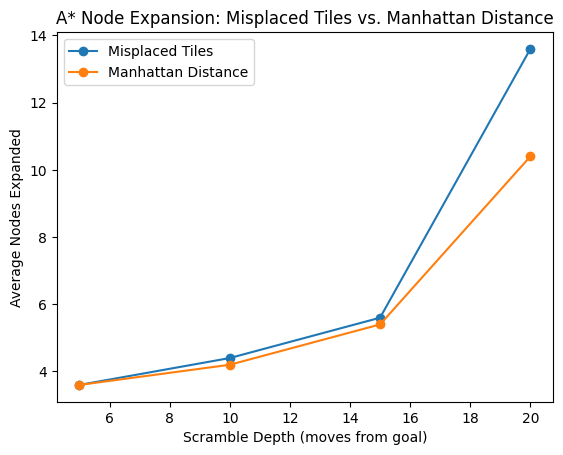

In [12]:
# Cell 16 — Table and graph
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(results)
summary = df.groupby("scramble_depth")[["misplaced_nodes", "manhattan_nodes"]].mean()
print(summary)

summary.plot(marker="o")
plt.xlabel("Scramble Depth (moves from goal)")
plt.ylabel("Average Nodes Expanded")
plt.title("A* Node Expansion: Misplaced Tiles vs. Manhattan Distance")
plt.legend(["Misplaced Tiles", "Manhattan Distance"])
plt.show()

## 5. Analysis

**1. Results table**

| Scramble depth | Misplaced Tiles (average nodes) | Manhattan Distance (average nodes) |
|---|---:|---:|
| 5 | 3.6 | 3.6 |
| 10 | 4.4 | 4.2 |
| 15 | 5.6 | 5.4 |
| 20 | 13.6 | 10.4 |

**2. Chart:** I made the comparison chart in Cell 16.

**3. Answers**

**Q1. When does the gap appear, and why does it increase?**  The first clear gap appears at depth **20** in my results. Harder puzzles usually need more searching, so the better Manhattan heuristic can save more work; random scrambles sometimes undo earlier moves, so the gap may not increase every time.

**Q2. Why is Manhattan Distance admissible, and why does it expand fewer nodes?**  Manhattan Distance is a stronger estimate but still never exceeds the real minimum moves. It helps A* focus on more useful states, so it generally checks fewer nodes.

**Optional experiment:**  For very difficult puzzles, Misplaced Tiles usually becomes slow sooner. Manhattan Distance also gets slower eventually, but often handles harder puzzles with fewer node expansions.
